In [ ]:
import torch
import torch.nn as nn
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

# Ustawienia ziarna dla powtarzalności
torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Urządzenie:", device)

# Pobranie i transformacja zbioru FashionMNIST
tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.2860,), (0.3530,))])
train_ds = torchvision.datasets.FashionMNIST("./data", train=True, download=True, transform=tf)
test_ds  = torchvision.datasets.FashionMNIST("./data", train=False, download=True, transform=tf)

train_dl = DataLoader(train_ds, batch_size=128, shuffle=True)
test_dl  = DataLoader(test_ds, batch_size=256, shuffle=False)

Urządzenie: cuda


100%|██████████| 26.4M/26.4M [00:02<00:00, 12.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 203kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.76MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 11.6MB/s]


In [ ]:
class CNN(nn.Module):
    def __init__(self, n_classes=10, pool="max"):
        super().__init__()
        def block(cin, cout):
            layers = [nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU()]
            if pool == "max":
                layers.append(nn.MaxPool2d(2))
            elif pool == "avg":
                layers.append(nn.AvgPool2d(2))
            elif pool == "stride":
                # Redukcja poprzez splot z krokiem 2
                layers += [nn.Conv2d(cout, cout, 3, stride=2, padding=1), nn.BatchNorm2d(cout), nn.ReLU()]
            return nn.Sequential(*layers)

        # Zbudowanie części splotowej (2 bloki)
        self.features = nn.Sequential(block(1, 32), block(32, 64))
        # Głowica: GAP + warstwa gęsta
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, n_classes))

    def forward(self, x):
        return self.head(self.features(x))

def evaluate(model, dl):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            correct += (out.argmax(1) == yb).sum().item()
            total += yb.numel()
    return correct / total

def train(model, epochs=6):
    model = model.to(device)
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)

    train_accs, test_accs = [], []
    for e in range(epochs):
        model.train()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            crit(model(xb), yb).backward()
            opt.step()

        train_accs.append(evaluate(model, train_dl))
        test_accs.append(evaluate(model, test_dl))
    return train_accs, test_accs

def count_parameters(m):
    return sum(p.numel() for p in m.parameters())

def get_feature_map_size(model, input_shape=(1, 1, 28, 28)):
    model.eval()
    dummy_input = torch.randn(input_shape).to(device)
    with torch.no_grad():
        fmap = model.features(dummy_input)
    return list(fmap.shape[1:]) # Wymiar mapy cech bez rozmiaru batcha

In [ ]:
variants = ["max", "avg", "stride"]
results = {}
EPOCHS = 6

for p in variants:
    print(f"Trenowanie wariantu: {p}...")
    # Reset ziarna przed każdym modelem dla sprawiedliwego porównania
    torch.manual_seed(42)
    m = CNN(pool=p).to(device)
    train_acc, test_acc = train(m, epochs=EPOCHS)

    params = count_parameters(m)
    fmap_size = get_feature_map_size(m)

    final_test = test_acc[-1]
    final_train = train_acc[-1]
    gap = final_train - final_test

    results[p] = {
        "train_accs": train_acc,
        "test_accs": test_acc,
        "params": params,
        "fmap_size": fmap_size,
        "final_test": final_test,
        "train_test_gap": gap
    }

headers = ["Wariant", "Liczba parametrów", "Rozmiar mapy cech", "Accuracy testowa", "Przerwa train-test"]
col_widths = [10, 20, 20, 18, 20]

header_line = " | ".join([f"{h:^{w}}" for h, w in zip(headers, col_widths)])
separator_line = "-" * len(header_line)

print(f"\n{header_line}")
print(separator_line)

for p in variants:
    res = results[p]
    fmap_str = f"[{res['fmap_size'][0]}, {res['fmap_size'][1]}, {res['fmap_size'][2]}]"
    params_str = f" {res['params']:,} "
    test_acc_str = f"{res['final_test'] * 100:.2f}%"
    gap_str = f"{res['train_test_gap'] * 100:.2f}%"

    row_values = [p, params_str, fmap_str, test_acc_str, gap_str]
    row_line = " | ".join([f"{val:^{w}}" for val, w in zip(row_values, col_widths)])
    print(row_line)

Trenowanie wariantu: max...
Trenowanie wariantu: avg...
Trenowanie wariantu: stride...

 Wariant   |  Liczba parametrów   |  Rozmiar mapy cech   |  Accuracy testowa  |  Przerwa train-test 
----------------------------------------------------------------------------------------------------
   max     |        19,658        |      [64, 7, 7]      |       82.95%       |        0.58%        
   avg     |        19,658        |      [64, 7, 7]      |       81.88%       |        0.85%        
  stride   |        66,026        |      [64, 7, 7]      |       88.22%       |        2.02%        


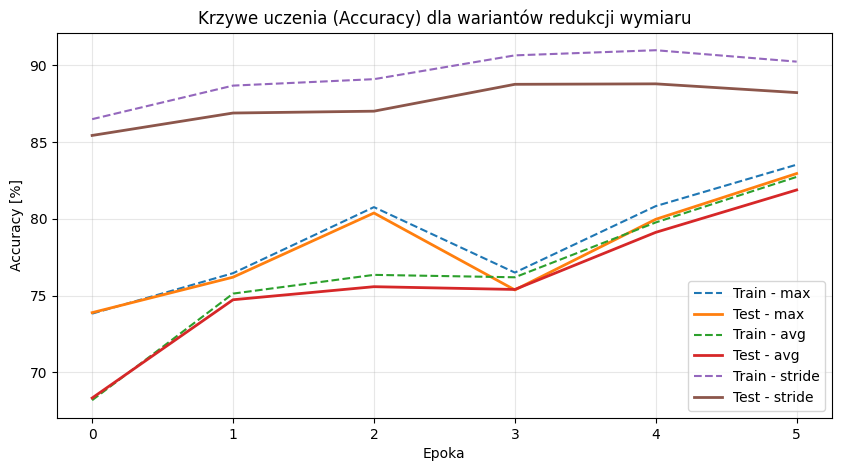

In [ ]:
# Rysowanie wykresów accuracy
plt.figure(figsize=(10, 5))
for p in variants:
    plt.plot([a * 100 for a in results[p]["train_accs"]], "--", label=f"Train - {p}")
    plt.plot([a * 100 for a in results[p]["test_accs"]], "-", linewidth=2, label=f"Test - {p}")
plt.xlabel("Epoka")
plt.ylabel("Accuracy [%]")
plt.title("Krzywe uczenia (Accuracy) dla wariantów redukcji wymiaru")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
